In [79]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import json
import os
from collections import Counter

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

# Load original dataset
jobs = pd.read_json("../data/raw/jobs.json")

# Create working copy
jobs_clean = jobs.copy()

print("Dataset loaded successfully!")
print("Dataset shape:", jobs_clean.shape)

Dataset loaded successfully!
Dataset shape: (1020, 8)


**Handle Missing Values**

In [80]:
jobs_clean['company'] = jobs_clean['company'].fillna('Unknown')

# Impute missing workplace types using mode
jobs_clean['workplace_type'] = jobs_clean['workplace_type'].fillna(
    jobs_clean['workplace_type'].mode()[0]
)

# Impute missing employment types using mode
jobs_clean['employment_type'] = jobs_clean['employment_type'].fillna('Unknown')

# Check missing values after imputation
print("Missing values after imputation:")
print(jobs_clean.isnull().sum())

Missing values after imputation:
id                   0
title                0
company              0
location             0
salary_range       400
workplace_type       0
employment_type      0
description          0
dtype: int64


**Clean Job Descriptions**

In [81]:
def clean_text(text):
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Normalize whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text


jobs_clean['clean_description'] = jobs_clean['description'].apply(clean_text)

print("Text cleaning completed successfully!")

Text cleaning completed successfully!


In [82]:
for i in range(3):

    print(f"\nJOB {i + 1}")
    print("=" * 80)

    print("Title:", jobs_clean.iloc[i]['title'])

    print("\nOriginal description:")
    print(jobs_clean.iloc[i]['description'][:500])

    print("\nCleaned description:")
    print(jobs_clean.iloc[i]['clean_description'][:500])


JOB 1
Title: Machine Learning Engineering Internship - Summer 2026

Original description:
What You’ll Do



Viant is seeking a Machine Learning Engineering Intern to support the development of data-driven and AI-powered solutions that fuel our programmatic advertising platform. This internship provides hands-on experience working alongside experienced ML engineers on real-world models and systems.

THE DAY-TO-DAY




Assist in developing, testing, and evaluating machine learning models and data pipelines
Work with large datasets to support model training, validation, and analysis
Col

Cleaned description:
what you’ll do viant is seeking a machine learning engineering intern to support the development of data-driven and ai-powered solutions that fuel our programmatic advertising platform. this internship provides hands-on experience working alongside experienced ml engineers on real-world models and systems. the day-to-day assist in developing, testing, and evaluating machine learning 

**Skills Extraction**

In [83]:
skills_dictionary = {
    "programming_languages": [
        "python", "java", "javascript", "c++", "c#",
        "ruby", "sql", "r programming", "matlab", "go",
        "typescript", "scala", "swift"
    ],

    "machine_learning_ai": [
        "machine learning", "deep learning",
        "artificial intelligence", "natural language processing",
        "nlp", "computer vision", "reinforcement learning",
        "generative ai", "neural networks", "predictive modeling"
    ],

    "data_science": [
        "data analysis", "data science", "data visualization",
        "statistics", "data mining", "data engineering",
        "data pipelines", "big data", "data modeling"
    ],

    "frameworks_libraries": [
        "tensorflow", "pytorch", "keras", "scikit-learn",
        "pandas", "numpy", "matplotlib", "seaborn",
        "opencv", "hugging face"
    ],

    "cloud_devops": [
        "aws", "azure", "google cloud", "gcp",
        "docker", "kubernetes", "jenkins",
        "ci/cd", "cloud computing"
    ],

    "databases_tools": [
        "mysql", "postgresql", "mongodb", "redis",
        "power bi", "tableau", "excel",
        "git", "github", "linux", "spark", "hadoop"
    ],

    "other_technical": [
        "data structures", "algorithms",
        "computer architecture", "gpu computing",
        "cuda", "opencl", "parallel programming",
        "high performance computing", "cybersecurity",
        "networking", "html", "css", "react", "node.js"
    ],

    "professional_skills": [
        "communication", "problem solving",
        "teamwork", "leadership", "project management",
        "critical thinking", "collaboration",
        "time management", "research"
    ]
}

print("Skills dictionary created successfully!")
print("Number of skill categories:", len(skills_dictionary))
print("Total skills:", sum(len(skills) for skills in skills_dictionary.values()))

Skills dictionary created successfully!
Number of skill categories: 8
Total skills: 86


In [84]:
def extract_skills(description, skills_dictionary):
    extracted_skills = {}

    for category, skills in skills_dictionary.items():
        matched_skills = []

        for skill in skills:
            pattern = r'(?<!\w)' + re.escape(skill) + r'(?!\w)'

            if re.search(pattern, description, re.IGNORECASE):
                matched_skills.append(skill)

        extracted_skills[category] = matched_skills

    return extracted_skills

In [85]:
jobs_clean['extracted_skills'] = jobs_clean['clean_description'].apply(
    lambda description: extract_skills(description, skills_dictionary)
)

print("Skill extraction completed successfully!")

Skill extraction completed successfully!


In [86]:
for index in range(3):
    print(f"\nJOB {index + 1}")
    print("Title:", jobs_clean.loc[index, 'title'])
    print("Extracted Skills:")

    for category, skills in jobs_clean.loc[index, 'extracted_skills'].items():
        if skills:
            print(f"{category}: {', '.join(skills)}")


JOB 1
Title: Machine Learning Engineering Internship - Summer 2026
Extracted Skills:
programming_languages: python, sql
machine_learning_ai: machine learning, artificial intelligence
data_science: data science, data pipelines
frameworks_libraries: tensorflow, pytorch, scikit-learn, pandas, numpy
cloud_devops: aws, gcp
other_technical: data structures

JOB 2
Title: NVIDIA 2026 Internships: Deep Learning Computer Architecture - US
Extracted Skills:
programming_languages: python, c++
machine_learning_ai: deep learning, neural networks
frameworks_libraries: tensorflow, pytorch, keras
other_technical: computer architecture, gpu computing, cuda, opencl, parallel programming

JOB 3
Title: Summer 2026 Intern - Undergrad User Research - Slack
Extracted Skills:
machine_learning_ai: artificial intelligence
data_science: statistics
professional_skills: communication, leadership, collaboration, research


In [87]:
jobs_clean['all_skills'] = jobs_clean['extracted_skills'].apply(
    lambda skill_dict: [
        skill
        for skills in skill_dict.values()
        for skill in skills
    ]
)

jobs_clean[['title', 'all_skills']].head(10)

,title,all_skills
0,Machine Learning Engineering Internship - Summer 2026,"[python, sql, machine learning, artificial intelligence, data science, data pipelines, tensorflo..."
1,NVIDIA 2026 Internships: Deep Learning Computer Architecture - US,"[python, c++, deep learning, neural networks, tensorflow, pytorch, keras, computer architecture,..."
2,Summer 2026 Intern - Undergrad User Research - Slack,"[artificial intelligence, statistics, communication, leadership, collaboration, research]"
3,Summer 2026 Engineering Intern,"[python, java, c#, big data, communication, leadership, time management]"
4,Applied AI Engineer (Internship),"[python, go, generative ai, cybersecurity, communication, collaboration]"
5,Summer 2026 Intern - Undergrad User Research - Slack,"[artificial intelligence, statistics, communication, leadership, collaboration, research]"
6,AI Engineer Intern,"[python, javascript, machine learning, artificial intelligence]"
7,NVIDIA 2026 Internships: Software Engineering - US,"[python, java, javascript, c++, sql, go, machine learning, deep learning, numpy, docker, kuberne..."
8,Python Developer - Ai Training,"[python, java, javascript, c++, go]"
9,Agentic AI Developer (Entry-Level),"[python, generative ai, azure, docker, ci/cd, git, github, communication, problem solving]"


In [88]:
technical_categories = [
    "programming_languages",
    "machine_learning_ai",
    "data_science",
    "frameworks_libraries",
    "cloud_devops",
    "databases_tools",
    "other_technical"
]

jobs_clean['technical_skills'] = jobs_clean['extracted_skills'].apply(
    lambda skill_dict: [
        skill
        for category in technical_categories
        for skill in skill_dict.get(category, [])
    ]
)

jobs_clean['professional_skills'] = jobs_clean['extracted_skills'].apply(
    lambda skill_dict: skill_dict.get('professional_skills', [])
)

In [89]:
from collections import Counter

all_skills = [
    skill
    for skills in jobs_clean['all_skills']
    for skill in skills
]

skill_counts = Counter(all_skills)

skills_frequency = pd.DataFrame(
    skill_counts.items(),
    columns=['skill', 'frequency']
).sort_values(by='frequency', ascending=False)

skills_frequency.head(20)

,skill,frequency
24,communication,462
0,python,412
28,java,365
35,javascript,308
42,react,285
11,aws,264
44,ci/cd,261
26,collaboration,252
39,git,237
1,sql,236


In [90]:
technical_skills_list = [
    skill
    for skills in jobs_clean['technical_skills']
    for skill in skills
]

technical_skill_counts = Counter(technical_skills_list)

technical_skills_frequency = pd.DataFrame(
    technical_skill_counts.items(),
    columns=['skill', 'frequency']
).sort_values(by='frequency', ascending=False)

technical_skills_frequency.head(20)

,skill,frequency
0,python,412
24,java,365
30,javascript,308
37,react,285
11,aws,264
39,ci/cd,261
34,git,237
1,sql,236
53,typescript,235
31,docker,186


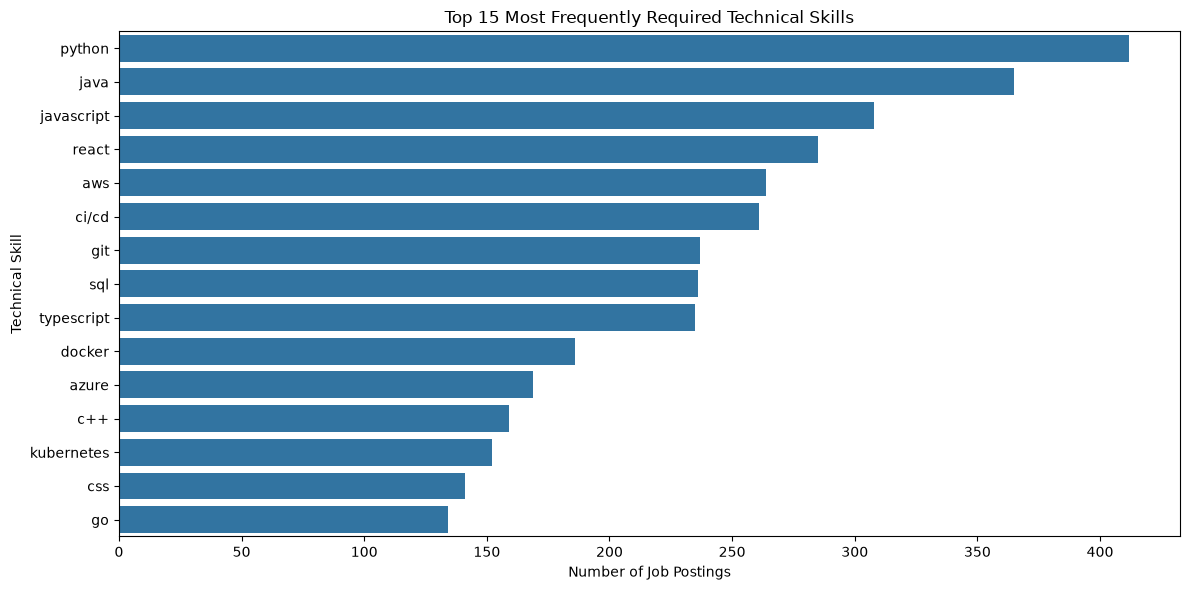

In [91]:
top_technical_skills = technical_skills_frequency.head(15)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_technical_skills,
    x='frequency',
    y='skill'
)

plt.title('Top 15 Most Frequently Required Technical Skills')
plt.xlabel('Number of Job Postings')
plt.ylabel('Technical Skill')
plt.tight_layout()
plt.show()

In [93]:
os.makedirs("../data/processed", exist_ok=True)

jobs_clean.to_csv(
    "../data/processed/jobs_cleaned.csv",
    index=False
)

print("Processed dataset saved successfully!")

Processed dataset saved successfully!
